In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, cohen_kappa_score,
    matthews_corrcoef, confusion_matrix, classification_report
)
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from imblearn.pipeline import Pipeline as ImbPipeline

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'
print("Task 3 modeling and class-balancing libraries loaded successfully.")

Task 3 modeling and class-balancing libraries loaded successfully.


In [2]:
csv_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(csv_path):
    csv_path = os.path.join("26-10-2026", "Task 3", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(csv_path)
print(f"Dataset successfully loaded: {df.shape[0]} rows, {df.shape[1]} columns")

num_features = [
    'Age', 'Rating', 'Positive Feedback Count', 'Review_Length',
    'Review_Word_Count', 'Exclamation_Count', 'Sentiment_Compound',
    'Sentiment_Pos', 'Sentiment_Neg', 'Positive_Word_Count',
    'Negative_Word_Count', 'Fit_Issue_Word_Count', 'Rating_x_Sentiment'
]
cat_features = ['Department Name', 'Division Name']
target = 'Recommended IND'

X = df[num_features + cat_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), num_features),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), cat_features)
    ]
)

X_train_trans = preprocessor.fit_transform(X_train)
X_test_trans = preprocessor.transform(X_test)
cat_cols = list(preprocessor.named_transformers_['cat'].get_feature_names_out(cat_features))
all_feature_names = num_features + cat_cols

print(f"Features engineered and standardized: {len(all_feature_names)} predictors.")

Dataset successfully loaded: 23486 rows, 23 columns
Features engineered and standardized: 20 predictors.


In [3]:
strategies = {}

lr_base = LogisticRegression(max_iter=1000, random_state=42)
lr_base.fit(X_train_trans, y_train)
strategies['Baseline (Unbalanced)'] = lr_base

lr_balanced = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_balanced.fit(X_train_trans, y_train)
strategies['Cost-Sensitive (Balanced Weights)'] = lr_balanced

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_trans, y_train)
lr_smote = LogisticRegression(max_iter=1000, random_state=42)
lr_smote.fit(X_train_smote, y_train_smote)
strategies['SMOTE Over-Sampling'] = lr_smote

rus = RandomUnderSampler(random_state=42)
X_train_rus, y_train_rus = rus.fit_resample(X_train_trans, y_train)
lr_rus = LogisticRegression(max_iter=1000, random_state=42)
lr_rus.fit(X_train_rus, y_train_rus)
strategies['Random Under-Sampling (RUS)'] = lr_rus

pipe_comb = ImbPipeline([
    ('smote', SMOTE(sampling_strategy=0.5, random_state=42)),
    ('rus', RandomUnderSampler(sampling_strategy=0.8, random_state=42)),
    ('lr', LogisticRegression(max_iter=1000, random_state=42))
])
pipe_comb.fit(X_train_trans, y_train)
strategies['Combined SMOTE + RUS'] = pipe_comb

balancing_records = []
for name, model in strategies.items():
    pred = model.predict(X_test_trans)
    prob = model.predict_proba(X_test_trans)[:, 1]
    
    acc = accuracy_score(y_test, pred)
    bal_acc = (recall_score(y_test, pred, pos_label=1) + recall_score(y_test, pred, pos_label=0)) / 2.0
    rec_0 = recall_score(y_test, pred, pos_label=0)
    prec_0 = precision_score(y_test, pred, pos_label=0, zero_division=0)
    f1_0 = f1_score(y_test, pred, pos_label=0)
    macro_f1 = f1_score(y_test, pred, average='macro')
    kappa = cohen_kappa_score(y_test, pred)
    mcc = matthews_corrcoef(y_test, pred)
    roc_auc = roc_auc_score(y_test, prob)
    pr_auc = average_precision_score(y_test, prob)
    
    balancing_records.append({
        'Balancing_Strategy': name,
        'Accuracy': round(acc, 4),
        'Balanced_Accuracy': round(bal_acc, 4),
        'Recall_Class0 (Dissatisfied)': round(rec_0, 4),
        'Precision_Class0': round(prec_0, 4),
        'F1_Class0': round(f1_0, 4),
        'Macro_F1': round(macro_f1, 4),
        'Cohen_Kappa': round(kappa, 4),
        'MCC': round(mcc, 4),
        'ROC_AUC': round(roc_auc, 4),
        'PR_AUC': round(pr_auc, 4)
    })

df_balancing = pd.DataFrame(balancing_records)
df_balancing.to_csv("class_balancing_methods_benchmark.csv", index=False)
df_balancing

,Balancing_Strategy,Accuracy,Balanced_Accuracy,Recall_Class0 (Dissatisfied),Precision_Class0,F1_Class0,Macro_F1,Cohen_Kappa,MCC,ROC_AUC,PR_AUC
0,Baseline (Unbalanced),0.9430,0.8958,0.8228,0.8513,0.8368,0.9011,0.8022,0.8024,0.9778,0.9948
1,Cost-Sensitive (Balanced Weights),0.9355,0.9401,0.9473,0.7533,0.8393,0.8995,0.7996,0.8078,0.9779,0.9948
2,SMOTE Over-Sampling,0.9364,0.9402,0.9461,0.7567,0.8409,0.9005,0.8017,0.8095,0.9774,0.9948
3,Random Under-Sampling (RUS),0.9355,0.9401,0.9473,0.7533,0.8393,0.8995,0.7996,0.8078,0.9782,0.9950
4,Combined SMOTE + RUS,0.9361,0.9400,0.9461,0.7560,0.8404,0.9003,0.8011,0.8090,0.9777,0.9948


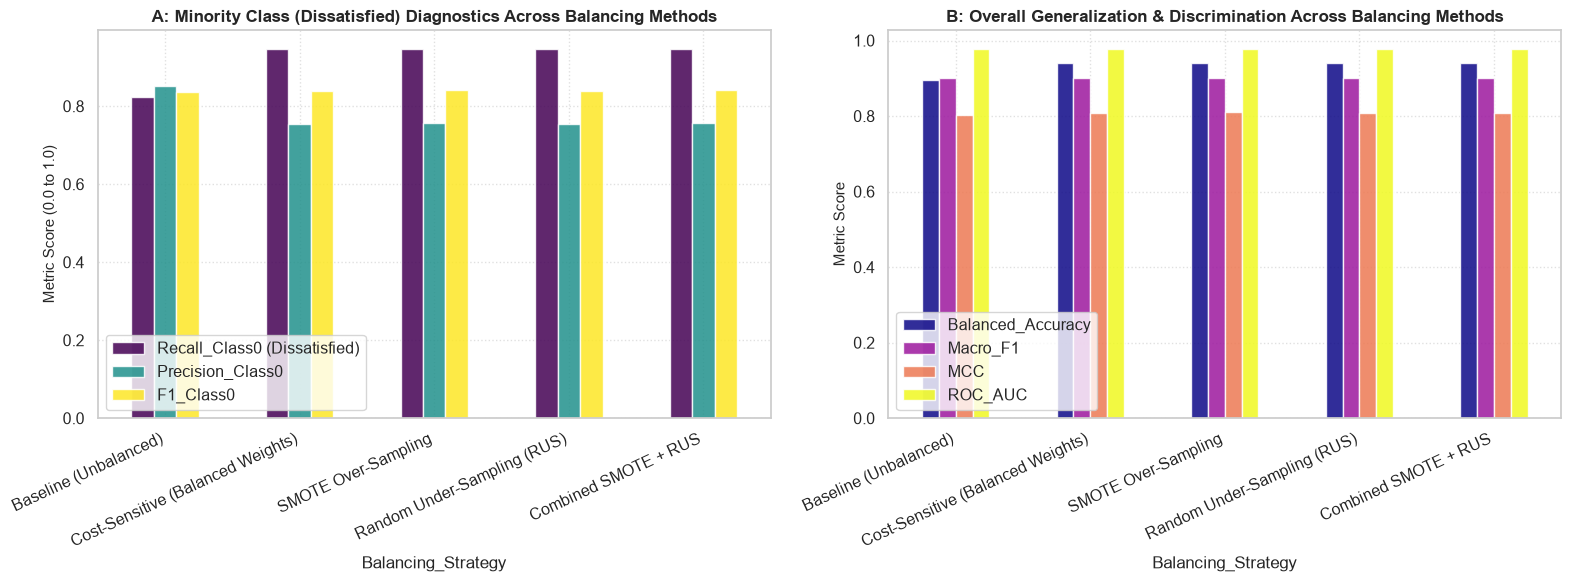

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

df_plot = df_balancing.set_index('Balancing_Strategy')
df_plot[['Recall_Class0 (Dissatisfied)', 'Precision_Class0', 'F1_Class0']].plot(
    kind='bar', ax=axes[0], colormap='viridis', alpha=0.85
)
axes[0].set_title("A: Minority Class (Dissatisfied) Diagnostics Across Balancing Methods", fontweight='bold', fontsize=12)
axes[0].set_ylabel("Metric Score (0.0 to 1.0)", fontsize=11)
axes[0].set_xticklabels(df_plot.index, rotation=25, ha='right')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='lower left', frameon=True)

df_plot[['Balanced_Accuracy', 'Macro_F1', 'MCC', 'ROC_AUC']].plot(
    kind='bar', ax=axes[1], colormap='plasma', alpha=0.85
)
axes[1].set_title("B: Overall Generalization & Discrimination Across Balancing Methods", fontweight='bold', fontsize=12)
axes[1].set_ylabel("Metric Score", fontsize=11)
axes[1].set_xticklabels(df_plot.index, rotation=25, ha='right')
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(loc='lower left', frameon=True)

plt.tight_layout()
plt.savefig("class_balancing_comparison_metrics.png", dpi=300)
plt.show()

C:\Users\panch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\panch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
C:\Users\panch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 

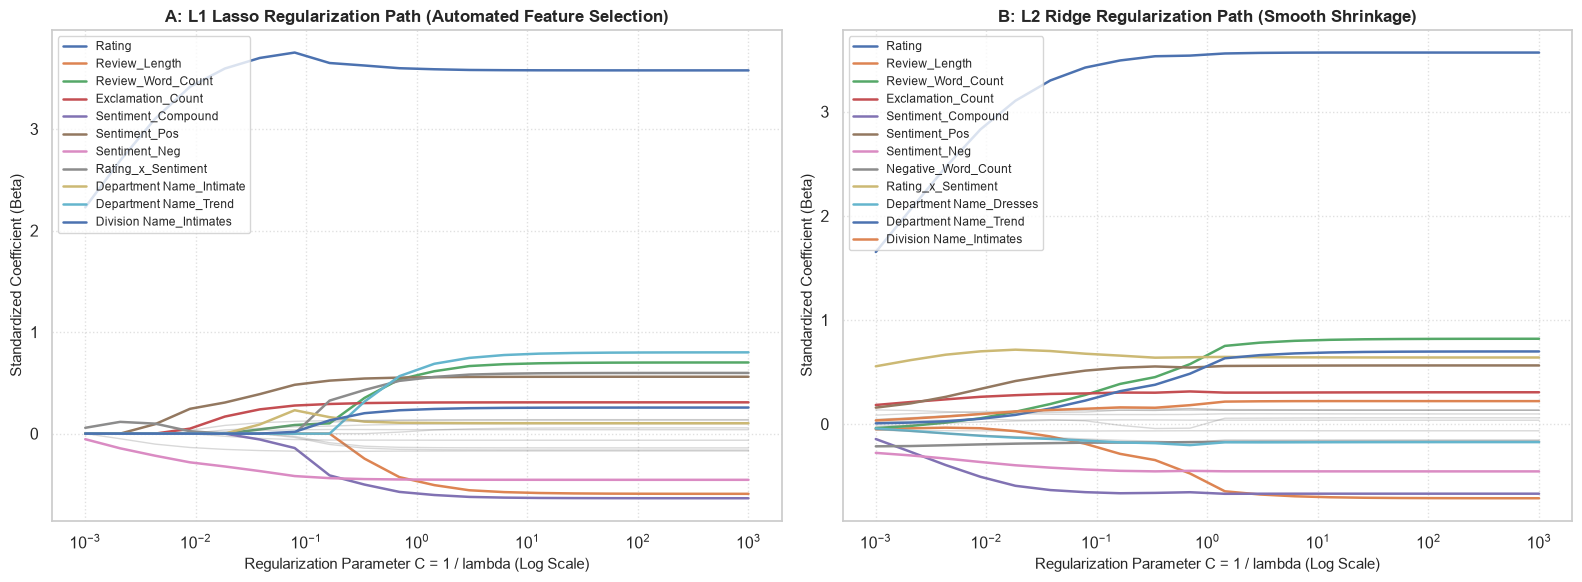

In [5]:
C_values = np.logspace(-3, 3, 20)
coefs_l1 = []
coefs_l2 = []

for c in C_values:
    clf_l1 = LogisticRegression(penalty='l1', C=c, solver='liblinear', random_state=42, max_iter=1000)
    clf_l1.fit(X_train_smote, y_train_smote)
    coefs_l1.append(clf_l1.coef_[0].copy())
    
    clf_l2 = LogisticRegression(penalty='l2', C=c, solver='lbfgs', random_state=42, max_iter=1000)
    clf_l2.fit(X_train_smote, y_train_smote)
    coefs_l2.append(clf_l2.coef_[0].copy())

coefs_l1 = np.array(coefs_l1)
coefs_l2 = np.array(coefs_l2)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for i, feat in enumerate(all_feature_names):
    if np.max(np.abs(coefs_l1[:, i])) > 0.20:
        axes[0].plot(C_values, coefs_l1[:, i], label=feat, linewidth=1.8)
    else:
        axes[0].plot(C_values, coefs_l1[:, i], color='grey', alpha=0.3, linewidth=1)
axes[0].set_xscale('log')
axes[0].set_title("A: L1 Lasso Regularization Path (Automated Feature Selection)", fontweight='bold', fontsize=12)
axes[0].set_xlabel("Regularization Parameter C = 1 / lambda (Log Scale)", fontsize=11)
axes[0].set_ylabel("Standardized Coefficient (Beta)", fontsize=11)
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='upper left', fontsize=8.5, frameon=True)

for i, feat in enumerate(all_feature_names):
    if np.max(np.abs(coefs_l2[:, i])) > 0.20:
        axes[1].plot(C_values, coefs_l2[:, i], label=feat, linewidth=1.8)
    else:
        axes[1].plot(C_values, coefs_l2[:, i], color='grey', alpha=0.3, linewidth=1)
axes[1].set_xscale('log')
axes[1].set_title("B: L2 Ridge Regularization Path (Smooth Shrinkage)", fontweight='bold', fontsize=12)
axes[1].set_xlabel("Regularization Parameter C = 1 / lambda (Log Scale)", fontsize=11)
axes[1].set_ylabel("Standardized Coefficient (Beta)", fontsize=11)
axes[1].grid(True, linestyle=':', alpha=0.6)
axes[1].legend(loc='upper left', fontsize=8.5, frameon=True)

plt.tight_layout()
plt.savefig("regularization_paths_logistic_regression.png", dpi=300)
plt.show()

In [6]:
prod_lr = LogisticRegression(penalty='l1', C=1.0, solver='liblinear', random_state=42, max_iter=1000)
prod_lr.fit(X_train_smote, y_train_smote)

coefs = prod_lr.coef_[0]
odds_ratios = np.exp(coefs)

X_des = np.hstack([np.ones((X_train_smote.shape[0], 1)), X_train_smote])
p_hat = prod_lr.predict_proba(X_train_smote)[:, 1]
W = p_hat * (1 - p_hat)
sub_idx = np.random.RandomState(42).choice(X_des.shape[0], size=5000, replace=False)
X_sub = X_des[sub_idx]
W_sub = W[sub_idx]
XT_W_X = np.dot(X_sub.T * W_sub, X_sub) + 1e-4 * np.eye(X_des.shape[1])
cov_matrix = np.linalg.pinv(XT_W_X) * (X_des.shape[0] / len(sub_idx))
se_coefs = np.sqrt(np.diag(cov_matrix)[1:])

ci_lower_or = np.exp(coefs - 1.96 * se_coefs)
ci_upper_or = np.exp(coefs + 1.96 * se_coefs)
z_stats = coefs / (se_coefs + 1e-9)
p_vals = 2 * (1 - stats.norm.cdf(np.abs(z_stats)))

interpretations = []
for f, or_val, c_val in zip(all_feature_names, odds_ratios, coefs):
    if c_val == 0:
        interpretations.append("Eliminated by L1 Lasso (Zero impact on recommendation)")
    elif or_val > 1.0:
        pct = (or_val - 1.0) * 100
        interpretations.append(f"+1 SD increases odds of recommendation by {pct:.1f}%")
    else:
        pct = (1.0 - or_val) * 100
        interpretations.append(f"+1 SD decreases odds of recommendation by {pct:.1f}%")

df_odds = pd.DataFrame({
    'Feature': all_feature_names,
    'Standardized_Coefficient (Beta)': np.round(coefs, 4),
    'Odds_Ratio (exp(Beta))': np.round(odds_ratios, 4),
    'OR_95_CI_Lower': np.round(ci_lower_or, 4),
    'OR_95_CI_Upper': np.round(ci_upper_or, 4),
    'p_value': [f"{p:.3e}" if p < 0.001 else f"{p:.4f}" for p in p_vals],
    'Retail_Business_Interpretation': interpretations
}).sort_values(by='Odds_Ratio (exp(Beta))', ascending=False)

df_odds.to_csv("logistic_regression_odds_ratios_interpretability.csv", index=False)
df_odds

C:\Users\panch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
C:\Users\panch\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(


,Feature,Standardized_Coefficient (Beta),Odds_Ratio (exp(Beta)),OR_95_CI_Lower,OR_95_CI_Upper,p_value,Retail_Business_Interpretation
1,Rating,3.5930,36.3415,12.6347,104.5301,2.638e-11,+1 SD increases odds of recommendation by 3534.2%
17,Department Name_Trend,0.6385,1.8937,0.0036,988.0396,0.8415,+1 SD increases odds of recommendation by 89.4%
4,Review_Word_Count,0.5786,1.7835,0.0964,33.0076,0.6976,+1 SD increases odds of recommendation by 78.4%
7,Sentiment_Pos,0.5539,1.7401,0.8377,3.6144,0.1375,+1 SD increases odds of recommendation by 74.0%
12,Rating_x_Sentiment,0.5412,1.7181,0.1827,16.1546,0.6360,+1 SD increases odds of recommendation by 71.8%
5,Exclamation_Count,0.3058,1.3577,0.7684,2.3990,0.2925,+1 SD increases odds of recommendation by 35.8%
19,Division Name_Intimates,0.2382,1.2690,0.0130,123.4985,0.9188,+1 SD increases odds of recommendation by 26.9%
18,Division Name_General Petite,0.1336,1.1430,0.5412,2.4138,0.7261,+1 SD increases odds of recommendation by 14.3%
0,Age,0.1321,1.1412,0.7929,1.6427,0.4771,+1 SD increases odds of recommendation by 14.1%
14,Department Name_Intimate,0.1058,1.1116,0.0134,92.0350,0.9625,+1 SD increases odds of recommendation by 11.2%


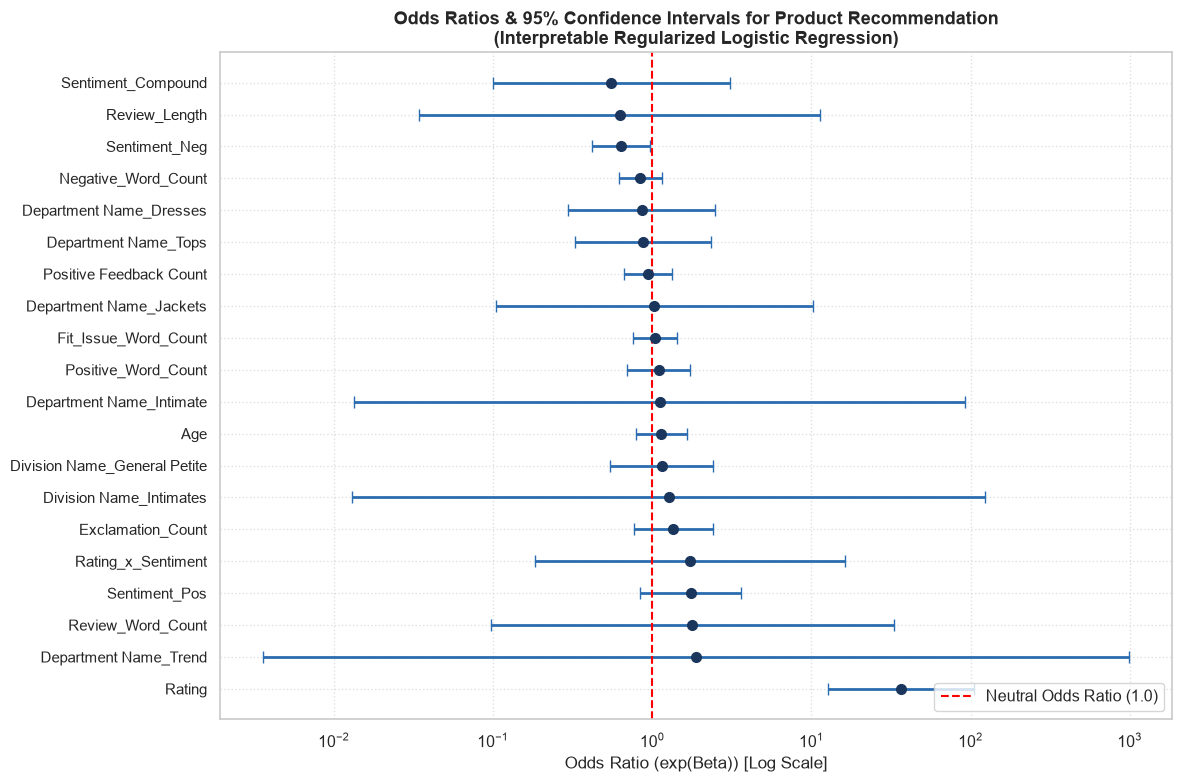

In [7]:
plt.figure(figsize=(12, 8))
df_active = df_odds[df_odds['Standardized_Coefficient (Beta)'] != 0].copy()
y_pos = np.arange(len(df_active))

plt.errorbar(
    df_active['Odds_Ratio (exp(Beta))'], y_pos,
    xerr=[df_active['Odds_Ratio (exp(Beta))'] - df_active['OR_95_CI_Lower'],
          df_active['OR_95_CI_Upper'] - df_active['Odds_Ratio (exp(Beta))']],
    fmt='o', color='#1A365D', ecolor='#2B6CB0', elinewidth=2, capsize=4, markersize=7
)
plt.axvline(1.0, color='red', linestyle='--', linewidth=1.5, label='Neutral Odds Ratio (1.0)')
plt.yticks(y_pos, df_active['Feature'], fontsize=10.5)
plt.xscale('log')
plt.xlabel("Odds Ratio (exp(Beta)) [Log Scale]", fontsize=12)
plt.title("Odds Ratios & 95% Confidence Intervals for Product Recommendation\n(Interpretable Regularized Logistic Regression)", fontweight='bold', fontsize=13)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='lower right', frameon=True)
plt.tight_layout()
plt.savefig("odds_ratios_interpretability_forest_plot.png", dpi=300)
plt.show()